### All linear regression analysis stuff

### Linear regression/diagnostics/cross validation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import seaborn as sns

from scipy import stats

In [2]:
data = pd.read_csv("dataset_2191_sleep.csv")
#clean data: drop question mark values
data = data[(data['max_life_span'] != '?') & (data['total_sleep'] != '?')]
data.info()

<class 'pandas.DataFrame'>
Index: 54 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           54 non-null     float64
 1   brain_weight          54 non-null     float64
 2   max_life_span         54 non-null     str    
 3   gestation_time        54 non-null     str    
 4   predation_index       54 non-null     int64  
 5   sleep_exposure_index  54 non-null     int64  
 6   danger_index          54 non-null     int64  
 7   total_sleep           54 non-null     str    
dtypes: float64(2), int64(3), str(3)
memory usage: 3.8 KB


In [3]:
#convert strings to floats
data["max_life_span"] = data["max_life_span"].astype(float)
data["total_sleep"] = data["total_sleep"].astype(float)
data.info()

<class 'pandas.DataFrame'>
Index: 54 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           54 non-null     float64
 1   brain_weight          54 non-null     float64
 2   max_life_span         54 non-null     float64
 3   gestation_time        54 non-null     str    
 4   predation_index       54 non-null     int64  
 5   sleep_exposure_index  54 non-null     int64  
 6   danger_index          54 non-null     int64  
 7   total_sleep           54 non-null     float64
dtypes: float64(4), int64(3), str(1)
memory usage: 3.8 KB


In [4]:
#define dependent and independent variables for later use
max_life_span = data["max_life_span"]
sleep_time = data["total_sleep"]


max_life_span = max_life_span.to_numpy()
sleep_time = sleep_time.to_numpy()
sleep_time = sleep_time.reshape(-1, 1)
max_life_span = max_life_span.reshape(-1, 1)

In [5]:
#split data
X_train, X_test, y_train, y_test = train_test_split(sleep_time, max_life_span, test_size=0.3, random_state=42)
#convert everything to numpy
#X_train = X_train.to_numpy()
#y_test = y_test.to_numpy()
#y_train = y_train.to_numpy()
#X_test = X_test.to_numpy()

#fix dimensions to make this work
X_test = X_test.reshape(-1, 1)
X_train = X_train.reshape(-1, 1)
y_train = y_train.reshape(-1, 1)

In [6]:
# Make sure dependent variables are 1D
y_train = y_train.ravel()
y_test = y_test.ravel()

In [7]:
#since X_train is only 35 -> chose k = 2 so that each time the model runs there is at least some meaningful amount of data
k = 2
kf = KFold(n_splits=k,shuffle=True,random_state=42)

In [8]:
#train model 
mse_ols_results = []


for (train, val) in kf.split(X_train):
    x_t, y_t = X_train[train], y_train[train]
    x_v, y_v = X_train[val], y_train[val]
    
    model1 = LinearRegression()
    model1.fit(x_t, y_t)

    # Predict on the validation observations
    predictions = model1.predict(x_v)
    
    # Calculate validation MSE
    mse = mean_squared_error(y_v, predictions)

    mse_ols_results.append(mse)

print(f"MSE from each fold: {mse_ols_results}")

MSE from each fold: [481.85459458123154, 200.68479859976387]


In [9]:
#average MSE from this model
avg_mse = sum(mse_ols_results)/len(mse_ols_results)
print(avg_mse)

341.2696965904977


In [10]:
#test model
#scikitlearn is being annoying, reshape other variables now as well
#run linear regression on the training data now:
model1 = model1.fit(X_train, y_train)

y_predicted = model1.predict(X_test)
test_mse = mean_squared_error(y_test, y_predicted)
print(test_mse)

289.7018706576074


In [12]:
slope = model1.coef_[0]
intercept = model1.intercept_

print(slope)
print(intercept)

-1.5265678243751688
34.33764594769425


Text(0.5, 1.0, 'Results of predictions on training data')

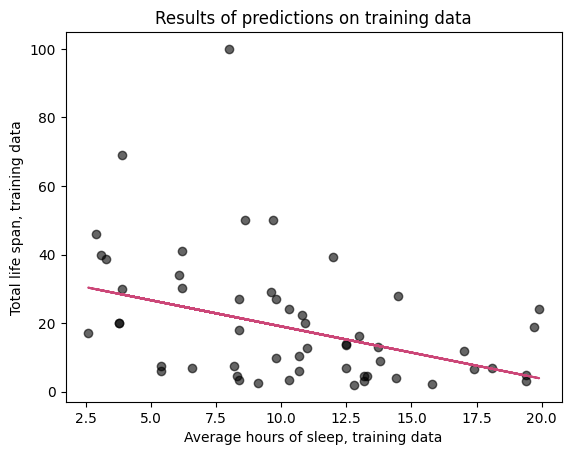

In [13]:
#y = slope * X_train + intercept
y = model1.predict(X_train)
plt.scatter(sleep_time, max_life_span, c = 'k', alpha = 0.6)
plt.plot(X_train, y, c= '#cc4778')
plt.xlabel("Average hours of sleep, training data")
plt.ylabel("Total life span, training data")
plt.title("Results of predictions on training data")

##### Comparison of predicted and actual values of test data

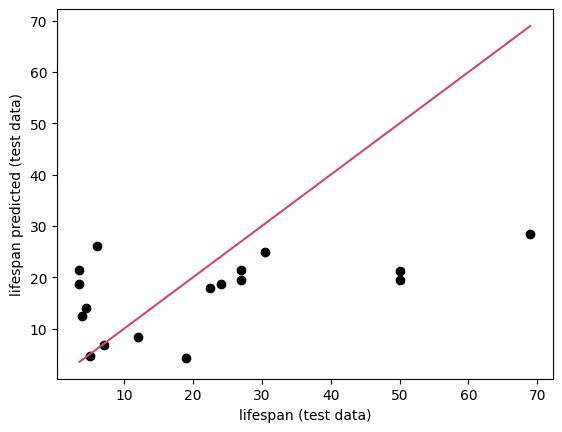

In [14]:
plt.scatter(y_test, y_predicted, c = 'k')
plt.xlabel("lifespan (test data)")
plt.ylabel("lifespan predicted (test data)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='#cc4778') #reference line


### Diagnostics on model

In [15]:
def least_squares_diagnostics_train(X_train,y_train):
    model1.fit(X_train, y_train)

    y_predicted = model1.predict(X_train)
    train_mse = mean_squared_error(y_train, y_predicted)

    #calculate ideal y values
    yhat = y_predicted
    #yhat = model.predict(X)
    #residuals: 
    residuals = y_train - y_predicted
    #calculate influence

    # calculate leverages
    H = X_train @ np.linalg.pinv(X_train.T @ X_train) @ X_train.T
    h_ii = np.diag(H) #leverages
    #calculate the standard residuals
    s_i = residuals / np.sqrt(train_mse * (1- h_ii)) #standard residuals
    
    #calculate cook's distance
    n = X_train.shape[0]
    p = X_train.shape[1]
    dof = n-p
    cook_distance = (s_i ** 2/p) * h_ii/(1-h_ii)
    
    
    #influence = model1.get_influence()
    #s_i = influence.resid_studentized_external # standard residuals
    #h_ii = influence.hat_matrix_diag # leverages
    h_grid = np.linspace(np.min(h_ii),np.max(h_ii),100)
    

    #specifications for degrees of freedom
    #n, p = X.shape
    #n, p = X_test.shape
    #dof = n - p # degrees of freedom
    l_thr = 2*p/n # leverage threshold
    d_thr = 4.0 /dof # cook's distance threshold
    s_cook = np.sqrt(d_thr * p * (1-h_grid) / h_grid)

    
#plotting
    fig, ax = plt.subplots(4,1,sharex=False,sharey=False, figsize=(6,15))

    plt.suptitle('Least squares diagnostics - on training data')
    # residual plot
    #ADD THE HORIZONTAL BAR
    ax[0].set_title('Residuals')
    ax[0].scatter(y, residuals, alpha =0.7, color = 'black')
    ax[0].hlines(0,np.min(y),np.max(y),linewidth=2, color = '#cc4778')
    ax[0].set_xlabel('maximum lifespan')
    ax[0].set_ylabel('Residuals')

    # q-q plot
    osm, osr = stats.probplot(s_i,dist='t',fit=False,sparams=(n-p-1))
    ax[2].set_title('Q-Q')
    ax[2].scatter(osm,osr, color = 'black', alpha =0.7)
    ax[2].plot(osm,osm, linewidth = 2, color = '#cc4778')
    ax[2].set_xlabel('Theoretical quantile')
    ax[2].set_ylabel('Real quantile')
    
    # scale-location plot
    ax[1].set_title('Scale-location')
    ax[1].scatter(yhat,np.sqrt(abs(s_i)), color = 'black', alpha =0.7)
    ax[1].set_xlabel('Predicted values')
    ax[1].set_ylabel('|Std. Res.|$^{1/2}$')
    
    # residuals vs leverage plot
    ax[3].set_title('Residuals vs leverage')
    ax[3].scatter(h_ii,s_i, alpha =0.7, color = 'black')
    if( np.min(s_cook) < np.max(s_i) or np.max(-s_cook) > np.min(s_i) ):
        plt.plot(h_grid,s_cook, color = '#cc4778', linewidth = 1)
        plt.plot(h_grid,-s_cook, color = '#cc4778', linewidth = 1)
    if( l_thr < 1.1 * np.max(h_ii) ):
        plt.vlines(l_thr,np.min(s_i),np.max(s_i), color = '#f2844b', linewidth = 1)
    if( np.max(s_i) > 2.5 or np.min(s_i) < -2.5 ):
        plt.hlines([-3,3],np.min(h_ii),np.max(h_ii),color = '#f2844b', linewidth = 1)
    ax[3].set_xlabel('Leverage')
    ax[3].set_ylabel('Std. Res.')

    
    plt.tight_layout()
    plt.show()

    return


# dark purple (check contrast): #8f0da4
#nice orange: #f2844b
#yellow option: #fca636

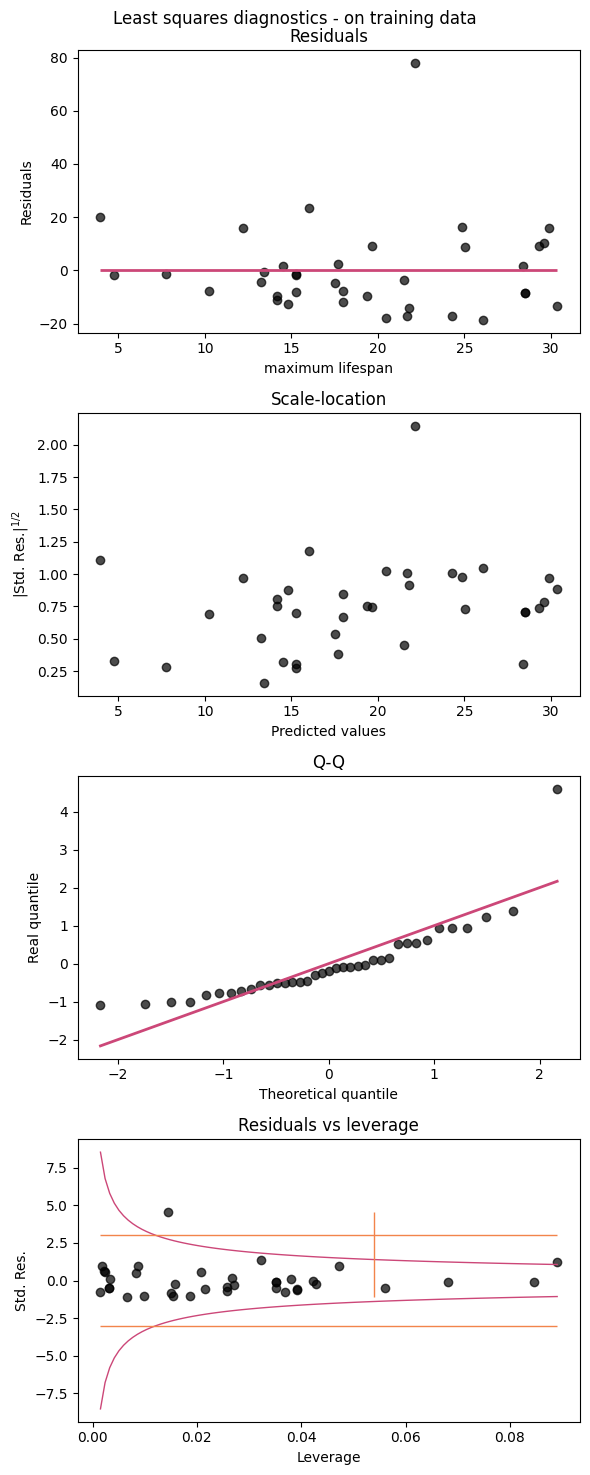

In [16]:
least_squares_diagnostics_train(X_train, y_train)

##### Diagnostics on TEST data

In [17]:
def least_squares_diagnostics_test(X_train,y_train):
    model1.fit(X_train, y_train)

    y_predicted_test = model1.predict(X_test)
    test_mse = mean_squared_error(y_test, y_predicted)

    #calculate ideal y values
    yhat = y_predicted_test
    #yhat = model.predict(X)
    #residuals: 
    test_residuals = y_test - y_predicted_test
    #calculate influence

    # calculate leverages
    H_test = X_test @ np.linalg.pinv(X_test.T @ X_test) @ X_test.T
    h_ii_test = np.diag(H_test) #leverages
    #calculate the standard residuals
    test_s_i = test_residuals / np.sqrt(test_mse * (1- h_ii_test)) #standard residuals
    
    #calculate cook's distance
    n = X_train.shape[0]
    p = X_train.shape[1]
    dof = n-p
    cook_distance = (test_s_i ** 2/p) * h_ii_test/(1-h_ii_test)
    
    
    #influence = model1.get_influence()
    #s_i = influence.resid_studentized_external # standard residuals
    #h_ii = influence.hat_matrix_diag # leverages
    h_grid = np.linspace(np.min(h_ii_test),np.max(h_ii_test),100)
    

    #specifications for degrees of freedom
    #n, p = X.shape
    #n, p = X_test.shape
    #dof = n - p # degrees of freedom
    l_thr = 2*p/n # leverage threshold
    d_thr = 4.0 /dof # cook's distance threshold
    s_cook = np.sqrt(d_thr * p * (1-h_grid) / h_grid)

    
#plotting
    fig, ax = plt.subplots(4,1,sharex=False,sharey=False, figsize=(6,15))

    plt.suptitle('Least squares diagnostics - on training data')
    # residual plot
    #ADD THE HORIZONTAL BAR
    ax[0].set_title('Residuals')
    ax[0].scatter(y_test, test_residuals, alpha =0.7, color = 'black')
    ax[0].hlines(0,np.min(y_test),np.max(y_test),linewidth=2, color = '#cc4778')
    ax[0].set_xlabel('maximum lifespan')
    ax[0].set_ylabel('Residuals')

    # q-q plot
    osm, osr = stats.probplot(test_s_i,dist='t',fit=False,sparams=(n-p-1))
    ax[2].set_title('Q-Q')
    ax[2].scatter(osm,osr, color = 'black', alpha =0.7)
    ax[2].plot(osm,osm, linewidth = 2, color = '#cc4778')
    ax[2].set_xlabel('Theoretical quantile')
    ax[2].set_ylabel('Real quantile')
    
    # scale-location plot
    ax[1].set_title('Scale-location')
    ax[1].scatter(yhat,np.sqrt(abs(test_s_i)), color = 'black', alpha =0.7)
    ax[1].set_xlabel('Predicted values')
    ax[1].set_ylabel('|Std. Res.|$^{1/2}$')
    
    # residuals vs leverage plot
    ax[3].set_title('Residuals vs leverage')
    ax[3].scatter(h_ii_test,test_s_i, alpha =0.7, color = 'black')
    if( np.min(s_cook) < np.max(test_s_i) or np.max(-s_cook) > np.min(test_s_i) ):
        plt.plot(h_grid,s_cook, color = '#cc4778', linewidth = 1)
        plt.plot(h_grid,-s_cook, color = '#cc4778', linewidth = 1)
    if( l_thr < 1.1 * np.max(h_ii_test) ):
        plt.vlines(l_thr,np.min(test_s_i),np.max(test_s_i), color = '#f2844b', linewidth = 1)
    if( np.max(test_s_i) > 2.5 or np.min(test_s_i) < - 2.5 ):
        plt.hlines([-3,3],np.min(h_ii_test),np.max(h_ii_test),color = '#f2844b', linewidth = 1)
    ax[3].set_xlabel('Leverage')
    ax[3].set_ylabel('Std. Res.')

    
    plt.tight_layout()
    plt.show()

    return

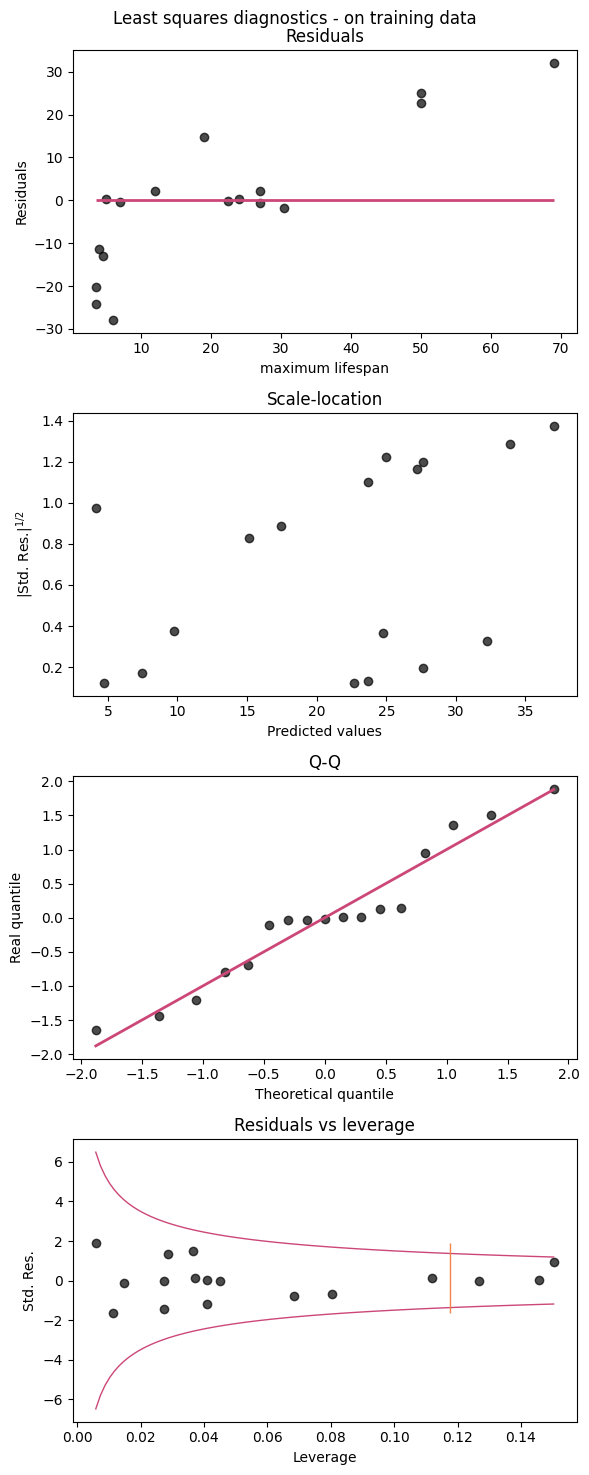

In [18]:
least_squares_diagnostics_test(X_test, y_test)

### Hypothesis testing on this data

#### hypothesis test on other regression model

In [19]:
#results = stats.linregress(x, y)

results = model1.predict(X_train)
#recall: slope is the coefficient of the model fitted on the training data
#print(results)

#all of this below is to accurately calculate the p values!

residuals = y_train - results

n = len(y_train)
p = X_train.shape[1]

dof = n - p - 1

variance_residuals = np.sum(residuals**2)/dof

X = np.column_stack((np.ones(n), X_train))

cov_matrix = variance_residuals * np.linalg.inv(X.T @ X)
standard_errors = np.sqrt(np.diag(cov_matrix))

t_value = float(np.asarray(slope).squeeze() / standard_errors[1])

#t_value = slope / standard_errors[1]

#p_value = 2 * stats.t.sf(np.abs(t_values), dof)
p_value = 2 * stats.t.sf(abs(t_value), dof)

#p_values = 2 * (1 - stats.t.cdf(np.abs(t_values), dof))
#dof_full_data = 
#print("p-value:", results.pvalues)

# address wierdness in the code here!
print(f'P-value: {p_value}')
alpha = 0.05
#p_values = results.pvalue
if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

P-value: 0.028335415320787646
Reject the null hypothesis.


### Bootstrapping

In [20]:
#def linear_regression(x, y):
#    results = stats.linregress(x, y)
#    return results.slope, results.intercept

#slope = model1.coef_[0]
#intercept = model1.intercept_

#rewrite function to work with the cross validated model
#x = sleep_time
#y = max_life_span

def linear_regression(X, y):
    X = np.asarray(X).reshape(-1, 1)
    y = np.asarray(y).ravel()
    model = LinearRegression()
    results = model.fit(X, y)
    return results.coef_[0], results.intercept_

a, b = linear_regression(X_train, y_train)

res = stats.bootstrap((np.asarray(X_train).ravel(),np.asarray(y_train).ravel()), linear_regression, confidence_level=0.95, paired=True, vectorized=False, random_state=42, axis = 0)

conf_int = res.confidence_interval
low = conf_int.low
high = conf_int.high

print("slope:     ", a, "[", low[0], ",", high[0], "]")
print("intercept: ", b, "[", low[1], ",", high[1], "]")
print("p-value:   ", p_value)

slope:      -1.5265678243751688 [ -2.439677171164744 , -0.5275304253203321 ]
intercept:  34.33764594769425 [ 22.793056937500342 , 49.383534320217336 ]
p-value:    0.028335415320787646


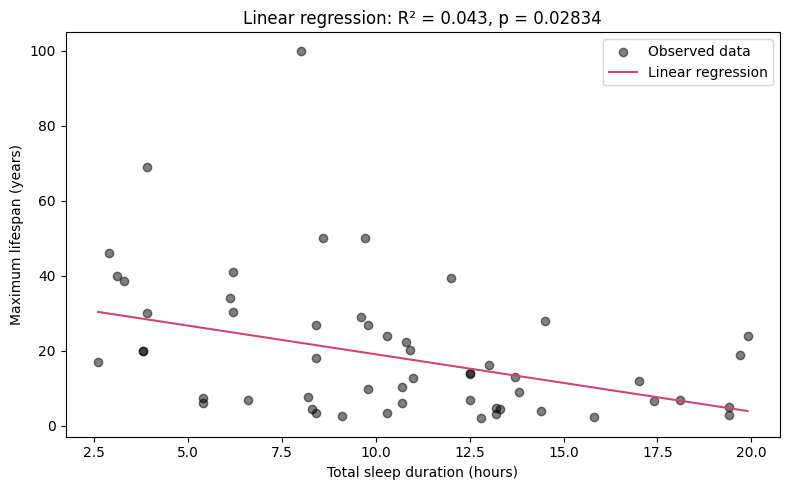

In [22]:
x_line = np.linspace(min(sleep_time), max(sleep_time), 100)
y_line = a * x_line + b

y_predicted = model1.predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(sleep_time, max_life_span, c='k', label='Observed data', alpha = 0.5)
plt.plot(x_line, y_line, color='#cc4778', label='Linear regression')
plt.xlabel('Total sleep duration (hours)')
plt.ylabel('Maximum lifespan (years)')
plt.title(f'Linear regression: R² = {r2_score(y_train, y_predicted):.3f}, p = {p_value:.4g}')
plt.legend()
plt.tight_layout()
plt.show()

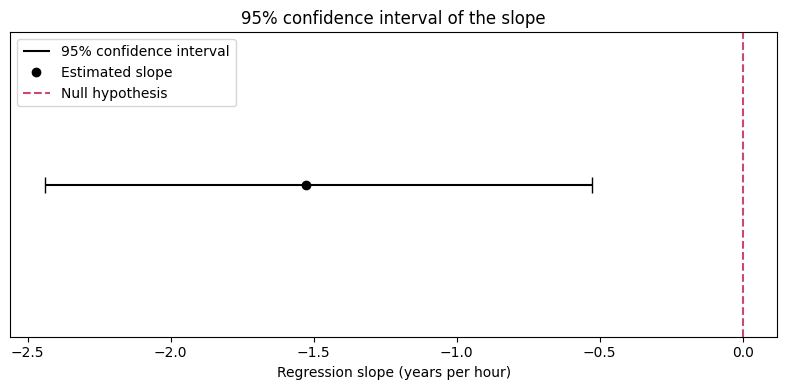

In [23]:
plt.figure(figsize=(8, 4))
plt.hlines(0, low[0], high[0], color='black', label='95% confidence interval')
plt.plot([low[0], high[0]], [0, 0], '|', color='black', markersize=12)
plt.plot(a, 0, 'ko', label='Estimated slope')
plt.axvline(0, color = '#cc4778', linestyle='--', label='Null hypothesis')
plt.xlabel('Regression slope (years per hour)')
plt.title('95% confidence interval of the slope')
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

A p-value below 0.05 provides evidence against the null hypothesis. If the bootstrap confidence interval excludes zero, it also supports a nonzero slope. The two methods need not always agree.

The slope describes the estimated change in maximum lifespan per additional hour of sleep. This is an association, not evidence of causation. The conventional slope test assumes independent observations, a linear mean relationship, constant residual variance and approximately normal errors. Shared evolutionary ancestry and omitted variables such as body mass may limit interpretation. This analysis uses all cleaned observations and is exploratory if the hypothesis was formulated after inspecting the data.

In [24]:
print(f"Slope: {a:.4f} years per hour")
print(f"95% bootstrap CI: [{low[0]:.4f}, {high[0]:.4f}]")
print(f"p-value: {p_value:.6g}")
if p_value < alpha:
    direction = 'negative' if a < 0 else 'positive'
    print(f"There is statistically significant evidence of a {direction} linear relationship.")
else:
    print("There is insufficient evidence of a nonzero linear slope.")

Slope: -1.5266 years per hour
95% bootstrap CI: [-2.4397, -0.5275]
p-value: 0.0283354
There is statistically significant evidence of a negative linear relationship.
